## Nurislam Aliyev

### Course: Deep Learning

### ID: 24B030024

### Instructor: Senior-Lecturer, Aidyn Abirov

#### Homework 4


In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Task 1 – GD on a curve with two valleys

In [3]:
w = -0.5
learning_rate = 0.1

def loss(w):
    return (w**2 - 1)**2

def gradient(w):
    return 4*w**3 - 4*w


for step in range(1):
    g = gradient(w)
    new_w = w - learning_rate * g
    new_L = loss(new_w)

    print(step+1, "w:", w, g, new_w, "loss:", new_L)

    w= new_w




1 w: -0.5 1.5 -0.65 loss: 0.3335062499999999


w = 0.5

1 w: 0.5 -1.5 0.65, loss: 0.3335062499999999

2 w: 0.65 -1.5015 0.80015, loss: 0.1294272414108005

w = -0.5

1 w: -0.5 1.5 -0.65, loss: 0.3335062499999999


In [4]:
w = 1.5
g = 7.5

for eta in [0.1, 0.2, 0.24]:
    new_w = w - eta * g
    print("eta:", eta, "w:", w, "g:", g, "new_w:", new_w)


eta: 0.1 w: 1.5 g: 7.5 new_w: 0.75
eta: 0.2 w: 1.5 g: 7.5 new_w: 0.0
eta: 0.24 w: 1.5 g: 7.5 new_w: -0.2999999999999998


eta: 0.1 w: 1.5 g: 7.5 new_w: 0.75 -> right valley

eta: 0.2 w: 1.5 g: 7.5 new_w: 0.0 -> on the bump

eta: 0.24 w: 1.5 g: 7.5 new_w: -0.2999999999999998 -> past the bump

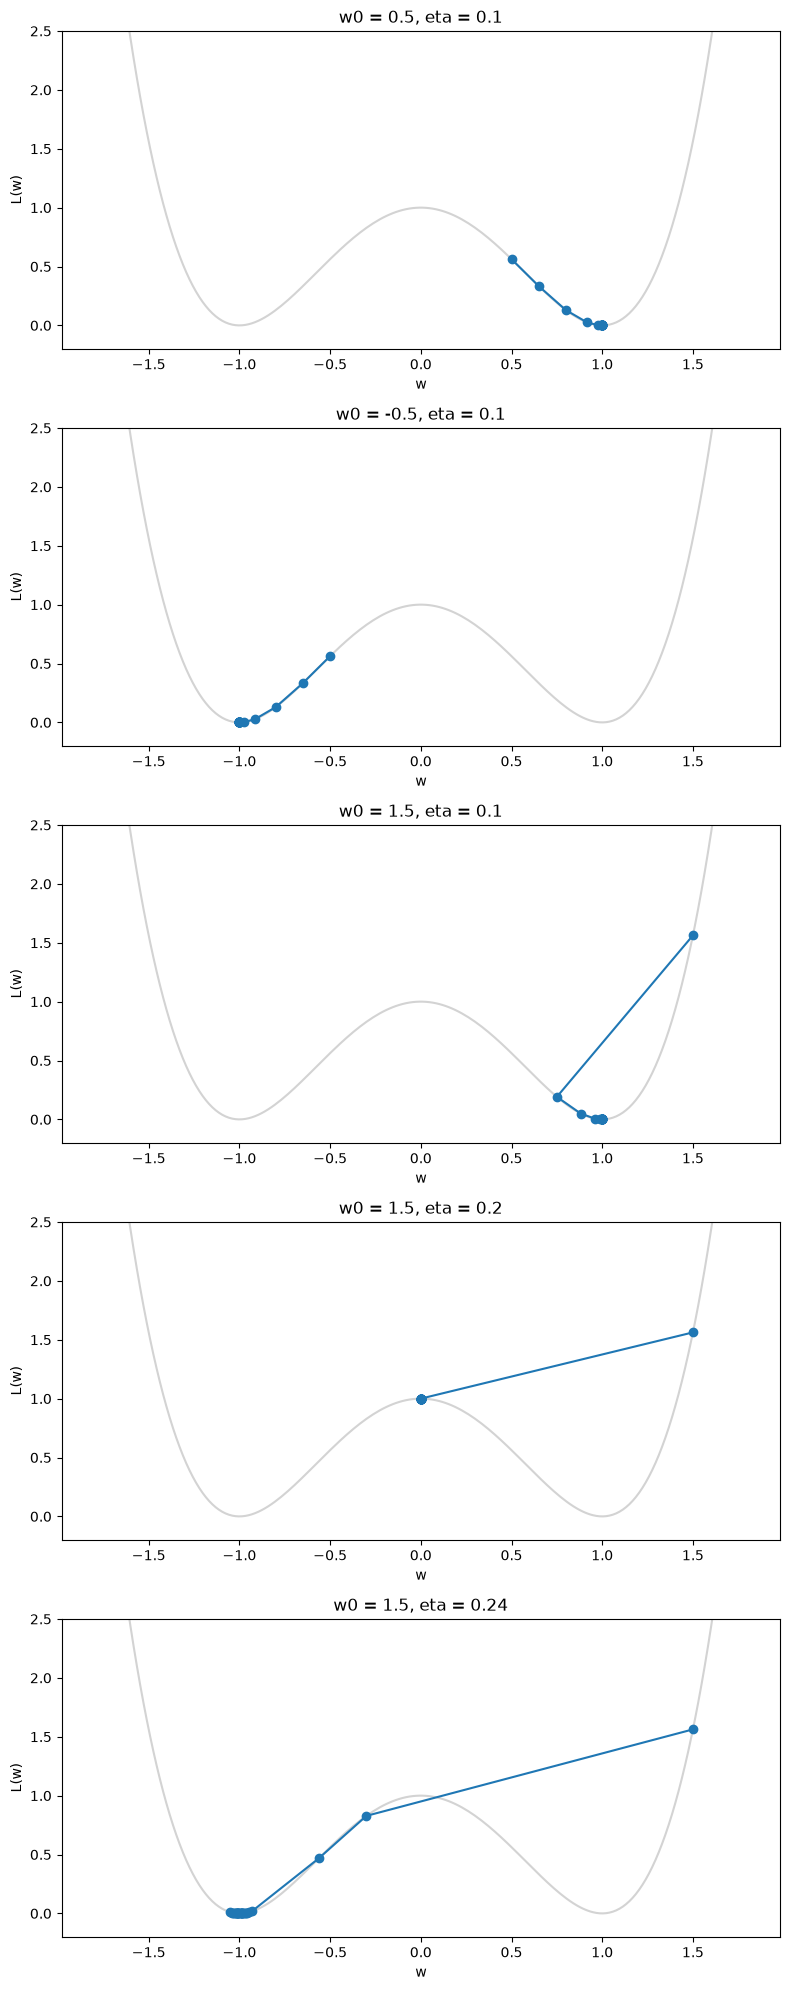

In [5]:
def gradient_descent(w0, eta, steps=30):
    points = [w0]
    w = w0
    for step in range(steps):
        g = gradient(w)
        w = w - eta * g
        points.append(w)

    return points

runs = [
    (0.5, 0.1),
    (-0.5, 0.1),
    (1.5, 0.1),
    (1.5, 0.2),
    (1.5, 0.24)
]

w_grid = np.linspace(-1.8, 1.8, 200)

fig, axes = plt.subplots(5, 1, figsize=(8, 20))

for ax, (w0, eta) in zip(axes, runs):

    points = gradient_descent(w0, eta)

    
    ax.plot(
        w_grid,
        (w_grid**2 - 1)**2,
        color="lightgray"
    )

    
    ax.plot(
        points,
        (np.array(points)**2 - 1)**2, # points = [w0, w1, ..., w30]
        "o-"
    )

    ax.set_ylim(-0.2, 2.5)
    ax.set_xlabel("w")
    ax.set_ylabel("L(w)")
    ax.set_title(f"w0 = {w0}, eta = {eta}")

plt.tight_layout()
plt.show()

## Task 2 – GD on a surface

1 1-w: (2, 1) (4, 20) (1.8, 0.0) 1-loss: 3.24
2 1-w: (1.8, 0.0) (3.6, 0.0) (1.62, 0.0) 1-loss: 2.6244000000000005
1 2-w: (2, 1) (4, 20) (1.6400000000000001, -0.7999999999999998) 2-loss: 9.089599999999997


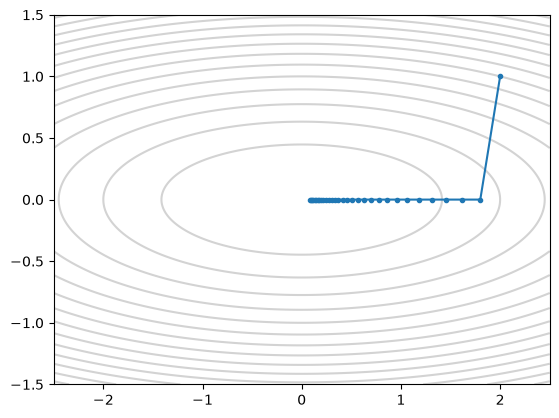

In [17]:
w1=2
w2=1

def loss(w1, w2):
    return w1**2 + 10 * w2**2

def g(w1, w2):
    return 2*w1, 20*w2

lr1 = 0.05
lr2 = 0.09

for step in range(2):
    g1, g2 = g(w1, w2)
    new_w1 = w1 - lr1 * g1
    new_w2 = w2 - lr1 * g2
    new_L = loss(new_w1, new_w2)

    print(step+1, "1-w:", (w1, w2), (g1, g2), (new_w1, new_w2), "1-loss:", new_L)

    w1 = new_w1
    w2 = new_w2

w1 = 2
w2 = 1

for step1 in range(1):
    g1, g2 = g(w1, w2)
    new_w1 = w1 - lr2 * g1
    new_w2 = w2 - lr2 * g2
    new_L = loss(new_w1, new_w2)

    print(step1+1, "2-w:", (w1, w2), (g1, g2), (new_w1, new_w2), "2-loss:", new_L)

    w1 = new_w1
    w2 = new_w2


def gradient_descent_2d(w1, w2, lr, steps=30):
    path = [(w1, w2)]

    for _ in range(steps):
        g1, g2 = g(w1, w2)

        w1 = w1 - lr * g1
        w2 = w2 - lr * g2

        path.append((w1, w2))

    return np.array(path)



path = gradient_descent_2d(2, 1, 0.05, 30)


w1, w2 = np.meshgrid(np.linspace(-2.5, 2.5, 200), np.linspace(-1.5, 1.5, 200))
plt.contour(w1, w2, w1**2 + 10 * w2**2, levels=15, colors="lightgray")
plt.plot(path[:, 0], path[:, 1], "o-", markersize=3) # path has shape (31, 2)
plt.xlim(-2.5, 2.5)
plt.ylim(-1.5, 1.5)
plt.show()
    

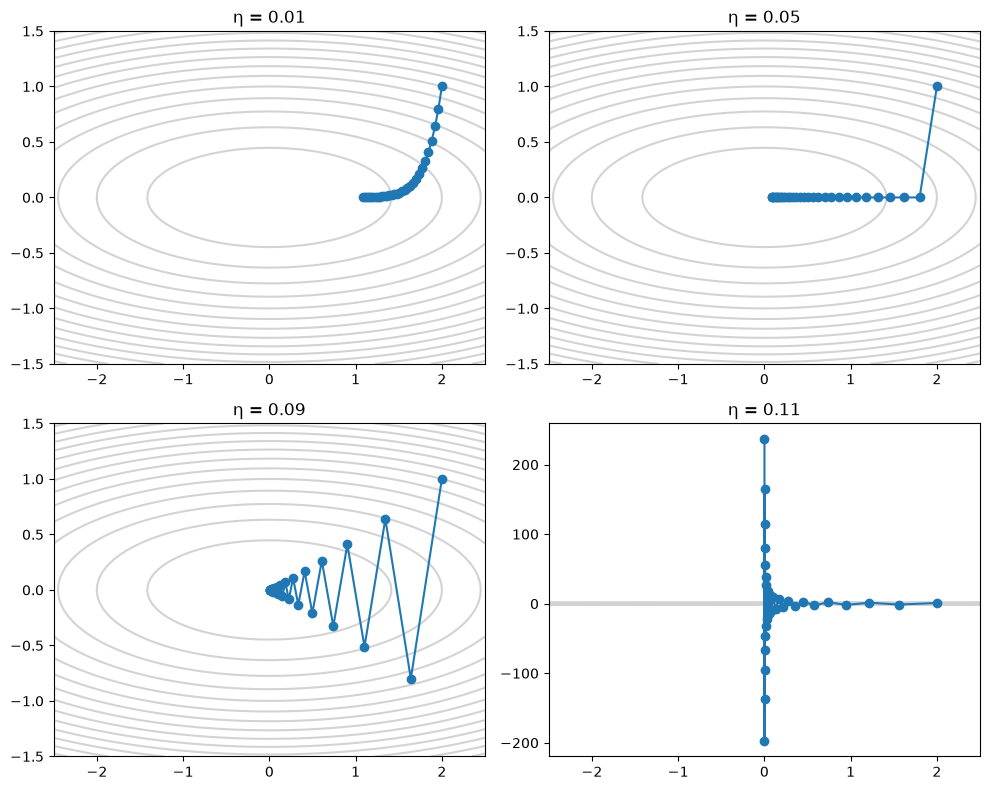

In [19]:
learning_rates = [0.01, 0.05, 0.09, 0.11]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, lr in zip(axes.flat, learning_rates):

    w1 = 2
    w2 = 1

    path = [(w1, w2)]
    loss_values = [loss(w1, w2)]

    for step in range(30):
        g1, g2 = g(w1, w2)

        w1 = w1 - lr * g1
        w2 = w2 - lr * g2

        path.append((w1, w2))
        loss_values.append(loss(w1, w2))

    path = np.array(path)

    w1_grid, w2_grid = np.meshgrid(
        np.linspace(-2.5, 2.5, 200),
        np.linspace(-1.5, 1.5, 200)
    )

    ax.contour(
        w1_grid,
        w2_grid,
        w1_grid**2 + 10*w2_grid**2,
        levels=15,
        colors="lightgray"
    )

    ax.plot(path[:, 0], path[:, 1], "o-")
    ax.set_title(f"η = {lr}")

plt.tight_layout()
plt.show()

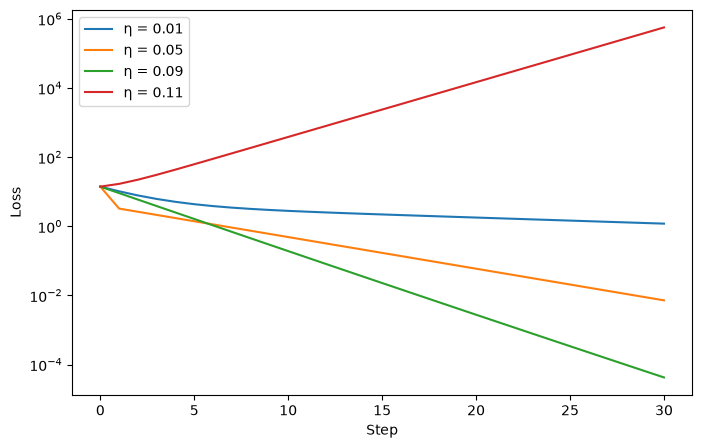

In [20]:
plt.figure(figsize=(8, 5))

for lr in learning_rates:

    w1 = 2
    w2 = 1
    loss_values = [loss(w1, w2)]

    for step in range(30):
        g1, g2 = g(w1, w2)

        w1 = w1 - lr * g1
        w2 = w2 - lr * g2

        loss_values.append(loss(w1, w2))

    plt.plot(loss_values, label=f"η = {lr}")

plt.yscale("log")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.legend()
plt.show()

Explanation

The path does not go straight to the minimum because the function is much steeper in the \(w_2\) direction than in the \(w_1\) direction. 

the gradient is larger for \(w_2\), so gradient descent moves more strongly in that direction.

with η = 0.01, the learning rate is too small, so the path moves toward the minimum slowly.

with η = 0.05, the first update gives the point (1.8, 0).

with η = 0.09, the path zig-zags in the \(w_2\) direction because the updates are large enough to overshoot \(w_2 = 0\) and change its 
sign. This happens because the gradient for \(w_2\) is \(20w_2\), while for \(w_1\) it is only \(2w_1\).

with η = 0.11, the learning rate is too large and the path blows up. The updates overshoot so much that the values move farther away from the minimum instead of getting closer.

## Task 3 – Watch GD fit a line

In [22]:
x = np.array([0., 1., 2., 3., 4.])
y = np.array([1., 3., 5., 7., 9.])

b = 0
w = 0

yhat = w * x + b


def loss(y_pred, y):
    return np.mean((y_pred - y)**2)

dL_dw = 2 * np.mean(yhat - y) * x
dL_db = 2 * np.mean(yhat - y)

mse = loss(yhat, y)

def gradients(w, b):
    yhat = w * x + b
    dL_dw = 2 * np.mean((yhat - y) * x)
    dL_db = 2 * np.mean(yhat - y)

    return dL_dw, dL_db

def gd(lr, n_updates):
    w = 0
    b = 0

    path = [(w, b)]
    history = [loss(w * x + b, y)]

    print("Starting loss:", history[0])

    for step in range(n_updates):
        dL_dw, dL_db = gradients(w, b)

        w = w - lr * dL_dw
        b = b - lr * dL_db

        path.append((w, b))
        history.append(loss(w * x + b, y))

    return np.array(path), np.array(history)


path, history = gd(0.05, 1)

print("Path:", path)
print("Loss:", history)

Starting loss: 33.0
Path: [[0.  0. ]
 [1.4 0.5]]
Loss: [33.    3.61]


Starting loss: 33.0


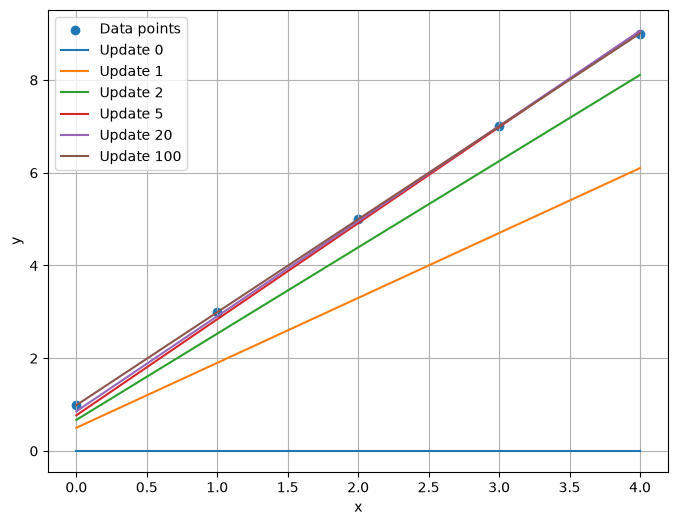

In [23]:
path, history = gd(0.05, 100)

updates = [0, 1, 2, 5, 20, 100]

plt.figure(figsize=(8, 6))

plt.scatter(x, y, label="Data points")

x_line = np.linspace(0, 4, 100)

for step in updates:
    w = path[step, 0]
    b = path[step, 1]

    y_line = w * x_line + b

    plt.plot(x_line, y_line, label=f"Update {step}")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

Starting loss: 33.0
Starting loss: 33.0
Starting loss: 33.0


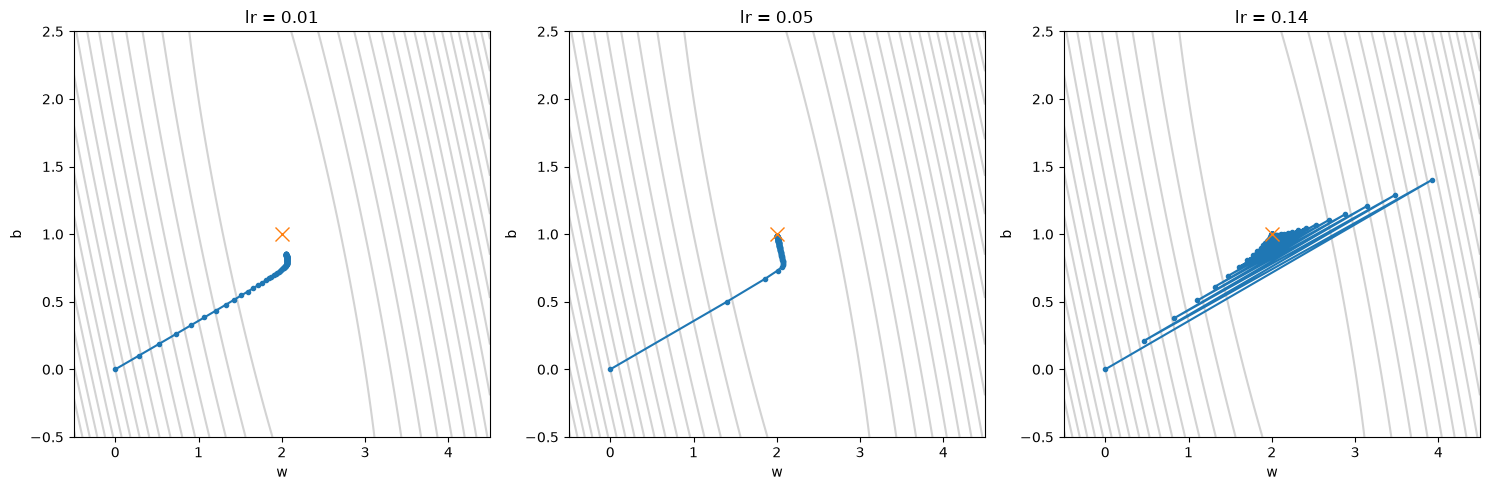

In [24]:
learning_rates = [0.01, 0.05, 0.14]

w_grid, b_grid = np.meshgrid(
    np.linspace(-0.5, 4.5, 200),
    np.linspace(-0.5, 2.5, 200)
)

loss_surface = (
    w_grid**2 * np.mean(x**2)
    + 2 * w_grid * b_grid * np.mean(x)
    + b_grid**2
    - 2 * w_grid * np.mean(x * y)
    - 2 * b_grid * np.mean(y)
    + np.mean(y**2)
)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, lr in zip(axes, learning_rates):
    path, history = gd(lr, 100)

    ax.contour(
        w_grid,
        b_grid,
        loss_surface,
        levels=20,
        colors="lightgray"
    )

    ax.plot(path[:, 0], path[:, 1], "o-", markersize=3)
    ax.plot(2, 1, "x", markersize=10)

    ax.set_title(f"lr = {lr}")
    ax.set_xlabel("w")
    ax.set_ylabel("b")
    ax.set_xlim(-0.5, 4.5)
    ax.set_ylim(-0.5, 2.5)

plt.tight_layout()
plt.show()

Starting loss: 33.0
Starting loss: 33.0
Starting loss: 33.0
Starting loss: 33.0


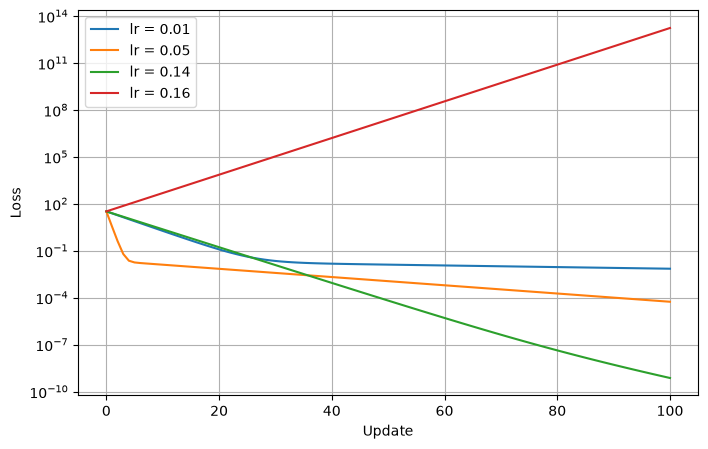

In [25]:
learning_rates = [0.01, 0.05, 0.14, 0.16]

plt.figure(figsize=(8, 5))

for lr in learning_rates:
    path, history = gd(lr, 100)
    plt.plot(history, label=f"lr = {lr}")

plt.yscale("log")
plt.xlabel("Update")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

### Questions

**1.** `b` gets close to its correct value first. The contours are much narrower in the `b` direction, so the loss changes faster when `b` changes. Gradient descent therefore adjusts `b` more quickly than `w`.

**2.** With `lr = 0.14`, the path is wild at first because the updates are large and overshoot the minimum, but it still ends up better than `lr = 0.05` after 100 updates. With `lr = 0.16`, the learning rate is too large, so the updates become unstable and the loss grows instead of decreasing.

**3.** I would start with a small learning rate and test a few values. I would look at the loss curve and choose a learning rate that decreases the loss steadily without being unnecessarily slow or unstable.

### Defense

- `path` stores `(w, b)` after every update, including the starting point.
- `history` stores the loss at the same points.
- Therefore, with 100 updates, both have **101 entries**: the initial state + 100 updates.
- If the learning rate is doubled, the steps become larger. This can make training faster, but if it becomes too large, the path can overshoot and become unstable.